# Lindtomancy

*Une analyse récréationnelle des tablettes de chocolat obtenues dans les kilos surprise Lindt*

* Kilos surprise achetés en boutique Lindt Bordeaux (Hangar, 17 Quai de Bacalan, 33300 Bordeaux)
* Source prix et poids des tablettes : https://www.lindt.fr/shop/formats/tablette/tablettes

In [1]:
# Imports
import utils
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
from matplotlib.patches import Patch

In [2]:
# Données d'entrée
data_file = "chocolate.json"
objdata = utils.load_chocodata(data_file)

df_choco = utils.build_chocodataframe(objdata)
df_ident = utils.build_identitydataframe(objdata)
df_event = utils.build_eventdataframe(objdata)

ks = df_event[["Price (€)"]].copy()
ks["Paid €/kg"] = df_event["Price (€)"] / df_event["Weight (g)"]
ks["Retail eq. €/kg"] = [(df_ident.loc[df_choco.index, "Retail (€)"] * df_choco[s]).sum() for s in ks.index] / df_event["Weight (g)"]
ks["Ratio"] = ks["Paid €/kg"] / ks["Retail eq. €/kg"]

In [3]:
# Paramètres graphiques
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
COL = {"Noir": "#3b2314", "Lait": "#b5703a", "Blanc": "#e9d9a8"}
LEGEND = [Patch(color=c, label=t) for t, c in COL.items()]

tab = df_ident.assign(Count=df_choco.sum(axis=1))
tab["Color"] = tab["Type"].map(COL)
tab["Retail €/kg"] = tab["Retail (€)"] / tab["Weight (g)"] * 1e3

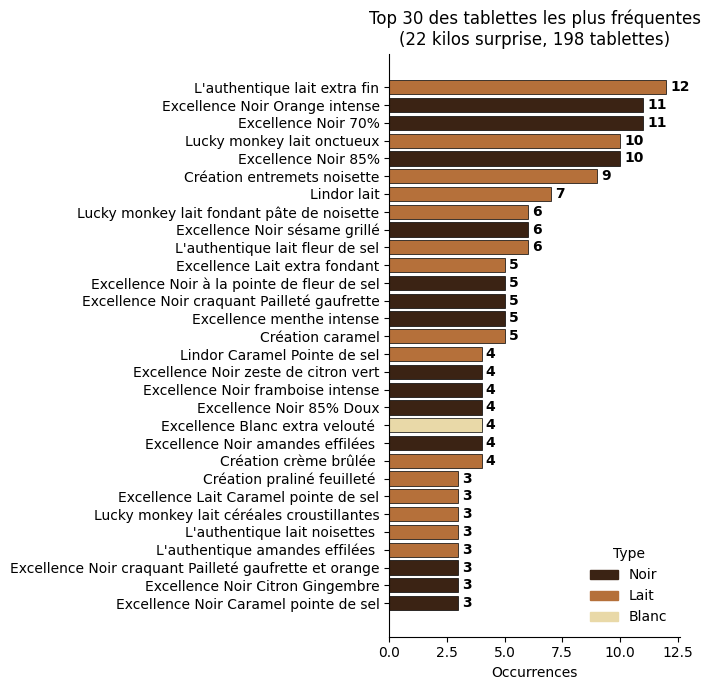

In [4]:
# Top tablettes
Ntop = 30
top = tab.nlargest(Ntop, "Count").sort_values("Count")
fig, ax = plt.subplots(figsize=(7, 7))
bars = ax.barh(top.index, top["Count"], color=top["Color"], edgecolor="k", lw=.5)
ax.bar_label(bars, padding=3, fontweight="bold")
ax.set(title=f"Top {Ntop} des tablettes les plus fréquentes\n({len(df_event)} kilos surprise, {int(tab.Count.sum())} tablettes)", xlabel="Occurrences")
ax.legend(handles=LEGEND, title="Type", loc="lower right", frameon=False)
plt.tight_layout(); plt.show()

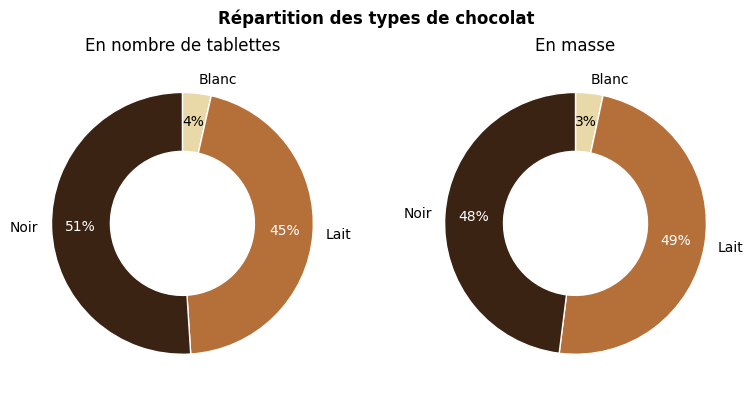

In [5]:
# Répartition des types de chocolat Noir/Lait/Blanc
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
for ax, (title, s) in zip(axes, {"En nombre de tablettes": tab.groupby("Type")["Count"].sum(),
                                  "En masse": (tab["Count"] * tab["Weight (g)"]).groupby(tab["Type"]).sum()}.items()):
    _, _, pct = ax.pie(s, labels=s.index, colors=[COL[t] for t in s.index], startangle=90, counterclock=False,
                       autopct="%1.0f%%", pctdistance=.78, wedgeprops=dict(width=.45, edgecolor="w"))
    for t, p in zip(s.index, pct): p.set_color("w" if t != "Blanc" else "k")
    ax.set_title(title)
fig.suptitle("Répartition des types de chocolat", fontweight="bold")
plt.tight_layout(); plt.show()

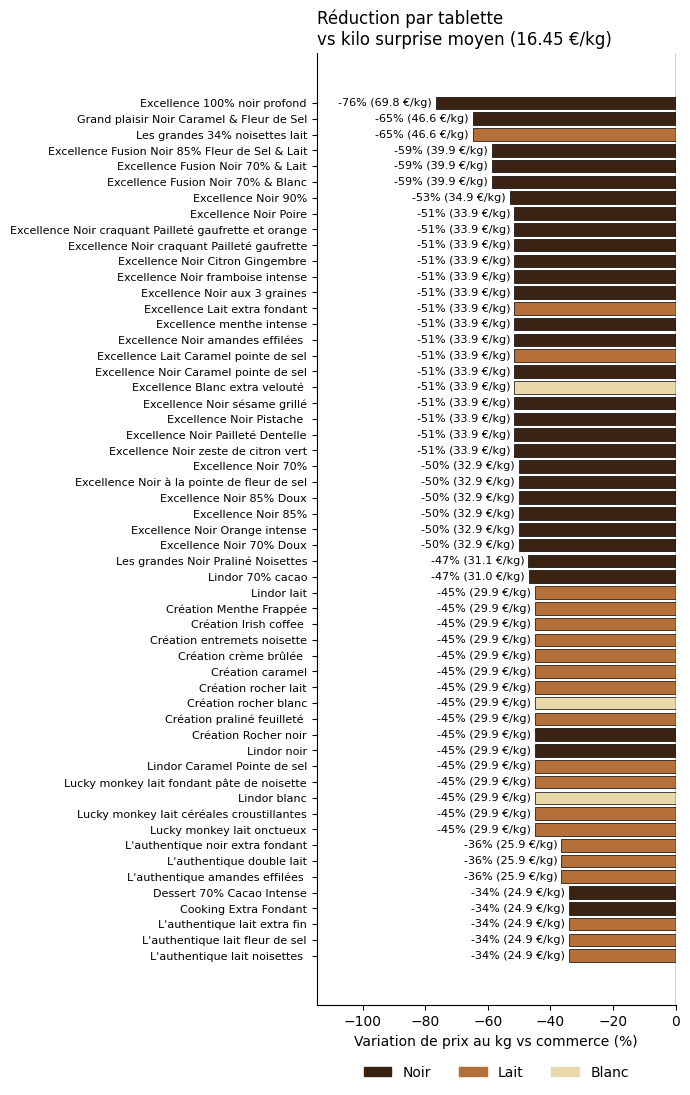

In [6]:
# Réduction équivalente par tablette
ks_kg = ks["Paid €/kg"].mean()
tab["Réduction (%)"] = (ks_kg / tab["Retail €/kg"] - 1) * 100   # < 0 : le kilo surprise est moins cher que la tablette en magasin
s = tab.sort_values("Réduction (%)", ascending=False)           # plus forte réduction en haut
fig, ax = plt.subplots(figsize=(7, 11))
bars = ax.barh(s.index, s["Réduction (%)"], color=s["Color"], edgecolor="k", lw=.5)
ax.bar_label(bars, labels=[f"{v:.0f}% ({r:.1f} €/kg)" for v, r in zip(s["Réduction (%)"], s["Retail €/kg"])], padding=3, fontsize=8)
ax.axvline(0, color="k", lw=1)
ax.margins(x=.5); ax.tick_params(axis="y", labelsize=8)
ax.set(xlabel="Variation de prix au kg vs commerce (%)")
ax.set_title(f"Réduction par tablette\nvs kilo surprise moyen ({ks_kg:.2f} €/kg)", loc="left")
ax.legend(handles=LEGEND, loc="upper center", bbox_to_anchor=(.5, -.05), ncol=3, frameon=False)
plt.tight_layout(); plt.show()

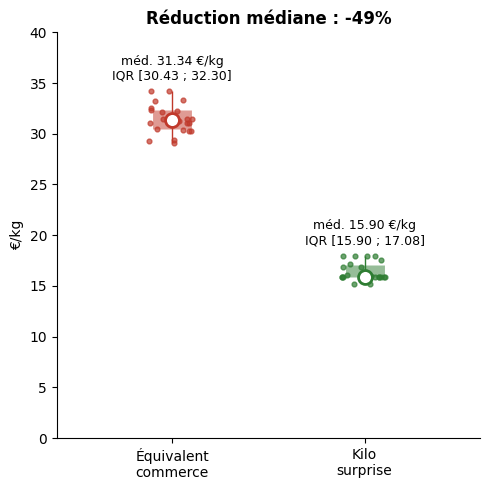

In [7]:
# Prix médians
fig, ax = plt.subplots(figsize=(5, 5))
for x, (col, c) in enumerate({"Retail eq. €/kg": "#c0392b", "Paid €/kg": "#2e7d32"}.items()):
    v = ks[col]; q1, med, q3 = v.quantile([.25, .5, .75])
    ax.vlines(x, v.min(), v.max(), color=c, lw=1)                      # étendue min-max
    ax.vlines(x, q1, q3, color=c, lw=28, alpha=.5)                     # IQR
    ax.plot(x, med, "o", color="w", mec=c, mew=2, ms=10, zorder=3)     # médiane
    ax.scatter(x + np.random.default_rng(0).uniform(-.12, .12, len(v)), v, s=12, color=c, alpha=.7)
    ax.annotate(f"méd. {med:.2f} €/kg\nIQR [{q1:.2f} ; {q3:.2f}]", (x, v.max()), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=9)
ax.set(xticks=[0, 1], xticklabels=["Équivalent\ncommerce", "Kilo\nsurprise"], xlim=(-.6, 1.6), ylim=(0, 40), ylabel="€/kg")
ax.set_title(f"Réduction médiane : -{(1 - ks['Ratio'].median()) * 100:.0f}%", fontweight="bold")
plt.tight_layout(); plt.show()